# ВВП и продолжительность жизни: что видно по данным стран

1. Как менялись ВВП на жителя и продолжительность жизни в 2000–2020 годах?
2. Действительно ли в странах с более высоким ВВП люди обычно живут дольше?
3. Насколько точно можно оценить продолжительность жизни по ВВП и году? Какие страны модель позволяет уверенно различить?

**Что означают показатели.** ВВП на душу населения — экономический показатель в расчёте на одного жителя. ППС означает, что при сравнении учитывают разницу цен между странами.

In [1]:
%matplotlib inline
# Библиотеки
from pathlib import Path

import matplotlib

if "__file__" in globals():
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler
from sklearn.tree import DecisionTreeRegressor

In [2]:
# Настройки отчёта
BASE_DIRECTORY = (
    Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
)
OUTPUT_DIRECTORY = BASE_DIRECTORY / "worldbank_outputs"
FIGURE_DIRECTORY = OUTPUT_DIRECTORY / "figures"
FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)

LAST_TRAIN_YEAR = 2015
BOOTSTRAP_REPEATS = 1000
RANDOM_SEED = 42
GDP_LABEL = "ВВП на душу по ППС, ед. файла"
LIFE_LABEL = "Ожидаемая продолжительность жизни, лет"
ECONOMY_LABEL = "Страна или территория"
INPUTS = ["gdp_ppp", "log_gdp", "year"]
BLUE, GREEN, RED = "#2769A3", "#007F73", "#C94A3D"

sns.set_theme(
    style="whitegrid",
    font="DejaVu Sans",
    rc={"axes.spines.top": False, "grid.alpha": 0.25},
)

In [3]:
# Вывод таблиц и графиков
def show_figure(fig, filename, layout_rect=None):
    """Сохранить график и показать его при запуске в ноутбуке."""
    fig.tight_layout(rect=layout_rect)
    fig.savefig(FIGURE_DIRECTORY / filename, dpi=160, bbox_inches="tight")
    if "__file__" not in globals():
        plt.show()
    plt.close(fig)


def show_table(table):
    labels = {"iso3": "Код страны", "year": "Год", "gdp_ppp": "ВВП на жителя по ППС",
              "life": "Продолжительность жизни, лет", "log_gdp": "Логарифм ВВП",
              "predicted": "Оценка модели, лет", "error": "Оценка минус факт, лет"}
    table = table.rename(columns=labels, index=labels)
    if table.index.name in labels:
        table.index.name = labels[table.index.name]
    try:
        from IPython.display import display
    except ImportError:
        pass
    else:
        display(table)




def thousands(value, _position):
    return f"{value / 1000:g} тыс." if value >= 1000 else f"{value:g}"


def format_gdp_axis(axis):
    """Настроить логарифмическую шкалу ВВП и показать деления в единицах файла."""
    axis.set(xscale="log", xlabel=GDP_LABEL + " (лог. шкала)")
    axis.set_xticks([1000, 3000, 10000, 30000, 100000])
    axis.xaxis.set_major_formatter(FuncFormatter(thousands))

## 1. Хватает ли данных для сравнения?

Сначала проверим, нет ли повторяющихся строк и невозможных значений. Затем посмотрим, где отсутствует ВВП. 


In [4]:
# Загрузка и проверка исходной таблицы
data = pd.read_csv(BASE_DIRECTORY / "39_worldbank.csv").sort_values(["iso3", "year"])
assert not data.duplicated(["iso3", "year"]).any()
assert data[["iso3", "year", "life"]].notna().all().all()
assert data["life"].between(0, 120).all() and data["gdp_ppp"].dropna().gt(0).all()

# Справочник хранится рядом с данными. Код остаётся ключом для объединения.
name_directory = pd.read_csv(BASE_DIRECTORY / "worldbank_economy_names_ru.csv")
economy_names = name_directory.set_index("iso3", verify_integrity=True)[ECONOMY_LABEL]
named_economies = data["iso3"].map(economy_names)
missing_names = data.loc[named_economies.isna(), "iso3"].unique()
if len(missing_names):
    raise ValueError(f"В справочнике нет названий для кодов {', '.join(missing_names)}")

data.insert(0, ECONOMY_LABEL, named_economies)
complete = data.dropna(subset=["gdp_ppp"]).copy()
complete["log_gdp"] = np.log(complete["gdp_ppp"])





quality = data[["iso3", "year", "gdp_ppp", "life"]].isna().sum().to_frame("Пропуски")
quality["Доля, %"] = 100 * quality["Пропуски"] / len(data)
show_table(quality.round(2))

/var/folders/_4/q5bzk7rx44s7kbm8qbfh8yfh0000gn/T/ipykernel_37789/1434470569.py:9: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  economy_names = name_directory.set_index("iso3", verify_integrity=True)[ECONOMY_LABEL]


,Пропуски,"Доля, %"
Код страны,0,0.00
Год,0,0.00
ВВП на жителя по ППС,431,9.46
"Продолжительность жизни, лет",0,0.00


,Страна или территория,Код,Лет без ВВП,Годы без ВВП
0,Американское Самоа,ASM,21,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007..."
1,Сен-Мартен (французская часть),MAF,21,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007..."
2,Британские Виргинские острова,VGB,21,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007..."
3,Венесуэла,VEN,21,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007..."
4,Южный Судан,SSD,21,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007..."
5,Французская Полинезия,PYF,21,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007..."
6,Северная Корея,PRK,21,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007..."
7,Новая Каледония,NCL,21,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007..."
8,Северные Марианские острова,MNP,21,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007..."
9,Нормандские острова,CHI,21,"2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007..."


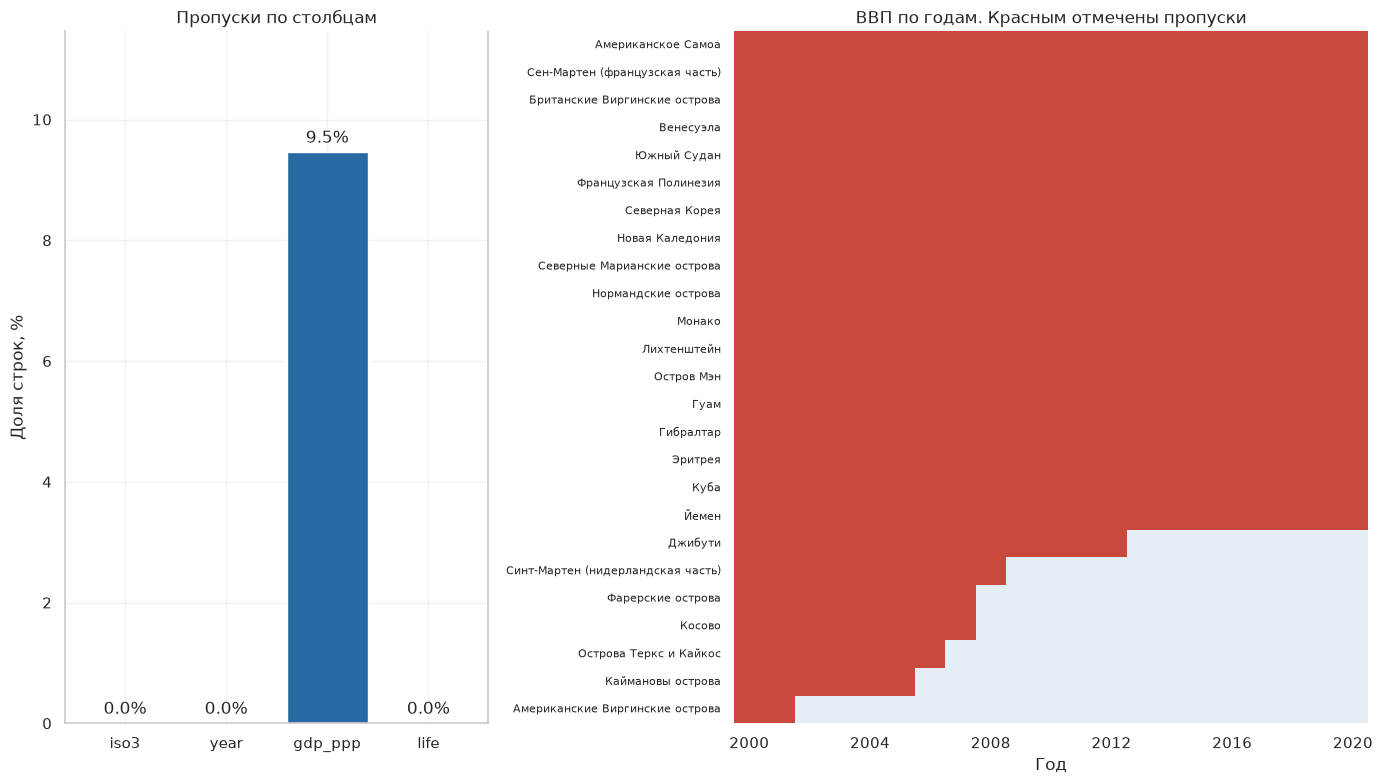

In [5]:
# Где сосредоточены пропуски ВВП
gdp_by_economy = data.pivot(index="iso3", columns="year", values="gdp_ppp")
gdp_panel = gdp_by_economy.dropna()

missing = gdp_by_economy.isna()
missing_counts = missing.sum(axis=1)
missing_codes = missing_counts[missing_counts > 0].sort_values(ascending=False).index
missing_grid = missing.loc[missing_codes].rename(index=economy_names)







missing_summary = pd.DataFrame({
    ECONOMY_LABEL: economy_names.reindex(missing_codes),
    "Код": missing_codes,
    "Лет без ВВП": missing_counts.reindex(missing_codes),
    "Годы без ВВП": [
        ", ".join(map(str, missing.columns[missing.loc[code]]))
        for code in missing_codes
    ],
}).reset_index(drop=True)
show_table(missing_summary)
missing_summary.to_csv(OUTPUT_DIRECTORY / "missing_gdp_countries.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].bar(quality.index, quality["Доля, %"], color=BLUE)
axes[0].set(title="Пропуски по столбцам", ylabel="Доля строк, %")
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=4)
axes[0].set_ylim(0, quality["Доля, %"].max() + 2)
sns.heatmap(
    missing_grid.astype(int), cmap=["#E6EEF5", RED], cbar=False,
    xticklabels=4, yticklabels=True, ax=axes[1],
)
axes[1].tick_params(axis="y", labelsize=8)
axes[1].set(title="ВВП по годам. Красным отмечены пропуски", xlabel="Год", ylabel="")
show_figure(fig, "01_missing.png")

**Что выяснили.** Из 4557 строк у 431 отсутствует ВВП — это 9,46% данных. Пропуски есть у 25 стран и территорий, у 18 из них ВВП не указан ни в одном году. Их названия приведены выше. В продолжительности жизни пропусков нет.

Для моделей остаётся 4126 строк. Для сравнения ВВП за весь период берём 192 страны и территории с данными за каждый год.

## 2. Какие значения встречаются чаще и зачем нужен логарифм?

На верхних графиках столбики показывают, сколько строк попало в каждый диапазон. Под ними короткие диаграммы показывают середину распределения и необычно далёкие значения.

У ВВП есть особенность: большинство значений сравнительно невелики, но несколько очень высоких растягивают шкалу. Чтобы остальные страны было легче разглядеть, используем логарифм ВВП. На такой шкале переход от 10 до 20 тысяч занимает столько же места, сколько переход от 20 до 40 тысяч.

Логарифм нужен и модели: он помогает описать ситуацию, когда увеличение ВВП на одну и ту же сумму связано с большей прибавкой жизни у бедных стран и меньшей у богатых.


,ВВП на жителя по ППС,"Продолжительность жизни, лет"
Строк с данными,4126.00,4557.00
Среднее,23289.08,70.60
Типичный разброс (стандартное отклонение),25117.54,8.91
Минимум,702.85,14.66
Граница нижней четверти,4919.28,65.03
Середина списка (медиана),13884.11,72.45
Граница верхней четверти,34275.00,77.26
Максимум,174569.52,86.15


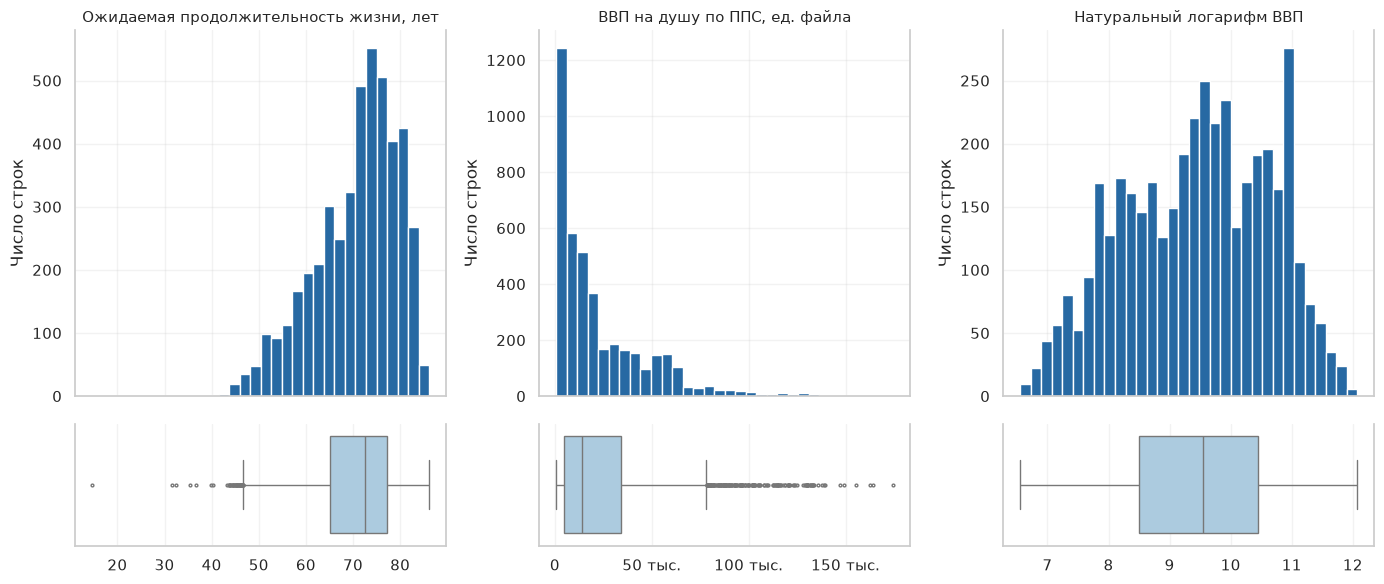

In [6]:
# Гистограммы и диаграммы размаха
description = data[["gdp_ppp", "life"]].describe().rename(index={
    "count": "Строк с данными", "mean": "Среднее", "std": "Типичный разброс (стандартное отклонение)",
    "min": "Минимум", "25%": "Граница нижней четверти", "50%": "Середина списка (медиана)",
    "75%": "Граница верхней четверти", "max": "Максимум",
})
show_table(description.round(2))
fig, axes = plt.subplots(2, 3, figsize=(14, 6), gridspec_kw={"height_ratios": [3, 1]})
for col, (key, label) in enumerate([
    ("life", LIFE_LABEL), ("gdp_ppp", GDP_LABEL), ("log_gdp", "Натуральный логарифм ВВП"),
]):
    values = complete[key] if key == "log_gdp" else data[key].dropna()
    axes[0, col].hist(values, bins=32, color=BLUE, edgecolor="white")
    axes[0, col].set_title(label, fontsize=11)
    axes[0, col].set_ylabel("Число строк")
    sns.boxplot(x=values, ax=axes[1, col], color="#A4CDE7", fliersize=2)
    axes[1, col].set_xlabel("")
    axes[0, col].sharex(axes[1, col])
    axes[0, col].tick_params(labelbottom=False)
axes[1, 1].xaxis.set_major_locator(MaxNLocator(nbins=4))
axes[1, 1].xaxis.set_major_formatter(FuncFormatter(thousands))
show_figure(fig, "02_distributions_outliers.png")

In [7]:
# Наблюдения за пределами 1,5 IQR
for column in ["gdp_ppp", "life"]:
    q1, q3 = data[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    flags = (data[column] < q1 - 1.5 * iqr) | (data[column] > q3 + 1.5 * iqr)
    pass

eda_columns = [ECONOMY_LABEL, "year", "gdp_ppp", "life"]
show_table(data.nsmallest(5, "life")[eda_columns].round(2))
show_table(data.nlargest(5, "gdp_ppp")[eda_columns].round(2))

,Страна или территория,Год,ВВП на жителя по ППС,"Продолжительность жизни, лет"
788,Центральноафриканская Республика,2009,1402.68,14.66
778,Центральноафриканская Республика,2019,1145.10,31.53
3705,Сомали,2011,1054.36,32.45
3741,Южный Судан,2017,NaN,35.35
3742,Южный Судан,2016,NaN,36.72


,Страна или территория,Год,ВВП на жителя по ППС,"Продолжительность жизни, лет"
2464,Макао,2013,174569.52,82.72
2465,Макао,2012,164239.26,82.47
2463,Макао,2014,162813.44,83.02
2466,Макао,2011,155385.32,82.47
3348,Катар,2011,149025.12,79.99


**Что видно по графикам.** Очень высокие значения ВВП встречаются редко. На обычной шкале они сжимают остальные наблюдения; после логарифмирования различия между странами заметнее.

В таблицах показаны самые низкие значения жизни и самые высокие значения ВВП.

## 3. Есть ли рост и связаны ли два показателя?

Сначала посмотрим на изменение показателей по годам. Линия на каждом графике медиана, то есть значение страны посередине упорядоченного списка. 

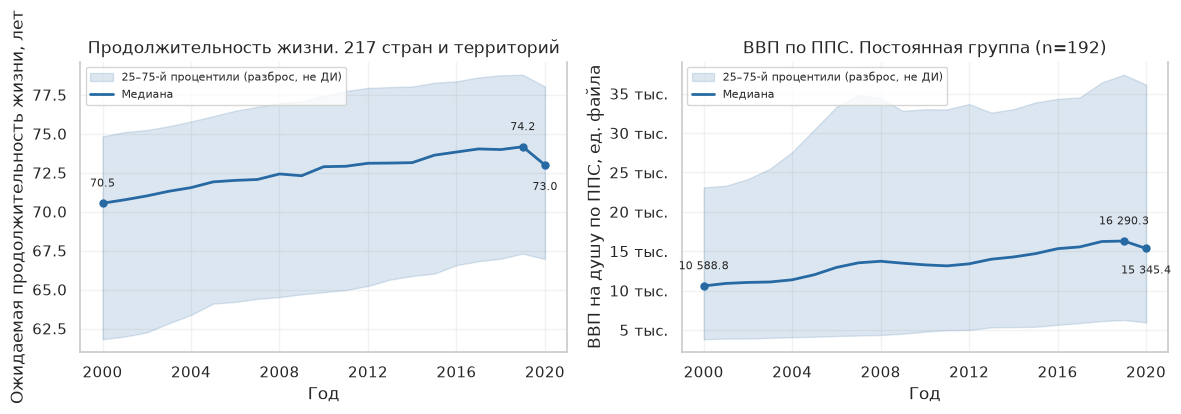

,"Медиана жизни, все страны/территории, лет","Медиана жизни, постоянная группа, лет","Медиана ВВП, постоянная группа"
Год,,,
2000,70.54,70.06,10588.78
2019,74.17,73.47,16290.34
2020,72.99,72.35,15345.41


In [8]:
# Медианы и квартильные диапазоны по годам
balanced = complete.loc[complete["iso3"].isin(gdp_panel.index)].copy()
life_trends = data.groupby("year")["life"].quantile([0.25, 0.5, 0.75]).unstack()
gdp_trends = balanced.groupby("year")["gdp_ppp"].quantile([0.25, 0.5, 0.75]).unstack()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, bands, label in zip(axes, [life_trends, gdp_trends], [LIFE_LABEL, GDP_LABEL]):
    axis.fill_between(
        bands.index,
        bands[0.25],
        bands[0.75],
        color=BLUE,
        alpha=0.16,
        label="25–75-й процентили (разброс, не ДИ)",
    )
    axis.plot(bands.index, bands[0.5], color=BLUE, linewidth=2, label="Медиана")
    axis.set(xlabel="Год", ylabel=label)
    axis.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
    axis.legend(loc="upper left", fontsize=8)
axes[0].set_title(f"Продолжительность жизни. {data.iso3.nunique()} стран и территорий")
axes[1].set_title(f"ВВП по ППС. Постоянная группа (n={balanced.iso3.nunique()})")
axes[1].yaxis.set_major_formatter(FuncFormatter(thousands))
for axis, series in zip(axes, [life_trends[0.5], gdp_trends[0.5]]):
    for year in [2000, 2019, 2020]:
        value = series.loc[year]
        axis.scatter(year, value, color=BLUE, s=25, zorder=3)
        axis.annotate(
            f"{value:,.1f}".replace(",", " "), (year, value),
            xytext=(0, 12 if year != 2020 else -18), textcoords="offset points",
            ha="center", fontsize=8,
        )
show_figure(fig, "03_time_trends.png")

declines = data.pivot(index="iso3", columns="year", values="life").diff(axis=1)[2020]
median_life = life_trends[0.5]





life_panel = data.pivot(index="iso3", columns="year", values="life")
trend_summary = pd.DataFrame({
    "Медиана жизни, все страны/территории, лет": median_life,
    "Медиана жизни, постоянная группа, лет": balanced.groupby("year")["life"].median(),
    "Медиана ВВП, постоянная группа": gdp_trends[0.5],
}).loc[[2000, 2019, 2020]]

show_table(trend_summary.round(2))
growth_2019 = 100 * (gdp_panel[2019] / gdp_panel[2000] - 1)
life_change_2019 = life_panel[2019] - life_panel[2000]

Медиана жизни выросла с 70.54 до 74.17 года. Рост жизни наблюдался у 213 из 217 стран и территорий. Медиана ВВП постоянной группы выросла примерно с 10 589 до 16 290 единиц файла.

В 2020 году произошёл спад

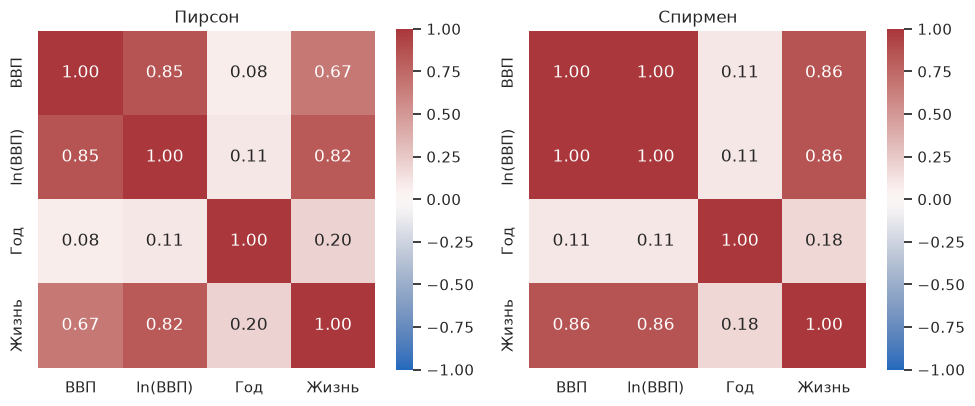

In [9]:
# Корреляции Пирсона и Спирмена
correlation_data = complete[["gdp_ppp", "log_gdp", "year", "life"]]
correlation_labels = {"gdp_ppp": "ВВП", "log_gdp": "ln(ВВП)", "year": "Год", "life": "Жизнь"}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for method, title, axis in zip(["pearson", "spearman"], ["Пирсон", "Спирмен"], axes):
    sns.heatmap(
        correlation_data.rename(columns=correlation_labels).corr(method=method),
        annot=True, fmt=".2f", center=0, vmin=-1, vmax=1,
        cmap="vlag", square=True, ax=axis,
    )
    axis.set_title(title)
show_figure(fig, "04_correlations.png")
pearson = correlation_data.corr()
spearman = correlation_data.corr(method="spearman")

Для ВВП и жизни коэффициент Пирсона равен 0,67, а для логарифма ВВП и жизни — 0,82. Пирсон оценивает, насколько точки похожи на прямую. Улучшение после логарифма согласуется с изгибом зависимости: рост жизни замедляется при высоком ВВП.

**Почему связь с годом маленькая, хотя линии росли?** Коэффициент года с жизнью — 0,20, с ВВП — 0,08. Между странами огромные различия, а их изменения за 20 лет на этом фоне меньше. Поэтому небольшой коэффициент по всем строкам не отменяет рост медианы.

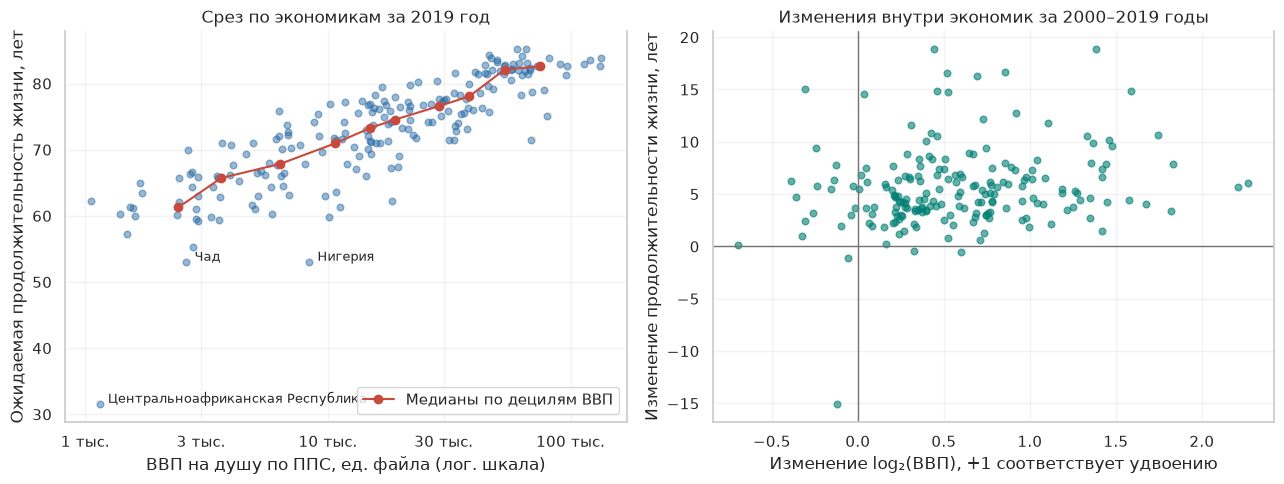

In [10]:
# Связь между экономиками и изменения внутри них
snapshot = complete.loc[complete["year"] == 2019]
# Группируем срез по децилям ВВП. Медианы показывают форму зависимости.
deciles = pd.qcut(snapshot["gdp_ppp"], 10)
snapshot_medians = snapshot.groupby(deciles, observed=True)[["gdp_ppp", "life"]].median()
start = balanced.loc[balanced["year"] == 2000].set_index("iso3")
end = balanced.loc[balanced["year"] == 2019].set_index("iso3")
changes = pd.DataFrame({
    "gdp_change": (end["log_gdp"] - start["log_gdp"]) / np.log(2),
    "life_change": end["life"] - start["life"],
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(snapshot["gdp_ppp"], snapshot["life"], color=BLUE, alpha=0.48, s=23)
axes[0].plot(
    snapshot_medians["gdp_ppp"], snapshot_medians["life"],
    color=RED, marker="o", label="Медианы по децилям ВВП",
)
axes[0].set(ylabel=LIFE_LABEL, title="Срез по экономикам за 2019 год")
format_gdp_axis(axes[0])
axes[0].legend(loc="lower right")
for _, row in snapshot.nsmallest(3, "life").iterrows():
    axes[0].annotate(
        row[ECONOMY_LABEL], (row["gdp_ppp"], row["life"]),
        xytext=(6, 1), textcoords="offset points", fontsize=9,
    )

axes[1].scatter(changes["gdp_change"], changes["life_change"], color=GREEN, alpha=0.6, s=23)
axes[1].axhline(0, color="0.45", linewidth=1)
axes[1].axvline(0, color="0.45", linewidth=1)
axes[1].set(
    title="Изменения внутри экономик за 2000–2019 годы",
    xlabel="Изменение log₂(ВВП), +1 соответствует удвоению",
    ylabel="Изменение продолжительности жизни, лет",
)
show_figure(fig, "05_income_and_life.png")

In [11]:
# Связь после учёта эффектов экономики и года
# Двойное центрирование убирает средние различия экономик и общие сдвиги по годам.
panel = balanced.loc[balanced["year"] <= 2019, ["iso3", "year", "log_gdp", "life"]]
indicators = ["log_gdp", "life"]
within = (
    panel[indicators]
    - panel.groupby("iso3")[indicators].transform("mean")
    - panel.groupby("year")[indicators].transform("mean")
    + panel[indicators].mean()
)

На левом графике сравниваем страны в одном 2019 году: более высокий ВВП обычно связан с большей продолжительностью жизни. Коэффициент для логарифма ВВП и жизни — 0,85.

На правом графике сравниваем, как изменилась каждая страна с 2000 по 2019 год. Один шаг вправо соответствует удвоению ВВП. Связь изменений гораздо слабее — 0,21.

То есть утверждение что богатые страны в среднем живут дольше поддерживается данными. А утверждение рост ВВП одной страны обязательно даст такой же прирост жизни из этого не следует.

## 4. Кто поднялся по ВВП и что означает место в рейтинге?

В таблице есть два варианта места: среди всех стран с данными в данном году и среди постоянной группы из 192 стран и территорий. Для движения по годам используем второй вариант.

In [12]:
# Места и годовые изменения для каждой экономики
first_year = int(gdp_panel.columns[0])
last_year = int(gdp_panel.columns[-1])
previous_year = last_year - 1

annual_rank_label = "Место среди всех с ВВП"
panel_rank_label = "Место в постоянной группе"

annual_rankings = data[[ECONOMY_LABEL, "iso3", "year", "gdp_ppp"]].copy()
annual_rankings["Экономик с ВВП в этом году"] = (
    annual_rankings.groupby("year")["gdp_ppp"].transform("count")
)
annual_rankings[annual_rank_label] = (
    annual_rankings.groupby("year")["gdp_ppp"]
    .rank(ascending=False, method="min")
    .astype("Int64")
)
panel_rows = annual_rankings["iso3"].isin(gdp_panel.index)
annual_rankings[panel_rank_label] = (
    annual_rankings.loc[panel_rows].groupby("year")["gdp_ppp"]
    .rank(ascending=False, method="min")
    .astype("Int64")
)
annual_rankings["Изменение ВВП за год, %"] = (
    annual_rankings.groupby("iso3")["gdp_ppp"].pct_change(fill_method=None) * 100
)
annual_rankings["Подъём за год в постоянной группе"] = (
    -annual_rankings.groupby("iso3")[panel_rank_label].diff()
)
annual_rankings.to_csv(
    OUTPUT_DIRECTORY / "economy_rankings_by_year.csv",
    index=False,
    encoding="utf-8-sig",
)

annual_leaders = (
    annual_rankings.loc[annual_rankings[annual_rank_label] <= 5]
    .groupby(["year", annual_rank_label])[ECONOMY_LABEL]
    .agg(" / ".join)
    .unstack()
)

show_table(annual_leaders)

Место среди всех с ВВП,1,2,3,4,5
Год,,,,,
2000,Люксембург,Бруней,Катар,Бермуды,ОАЭ
2001,Люксембург,Бермуды,Бруней,Катар,ОАЭ
2002,Люксембург,Бермуды,Бруней,Катар,ОАЭ
2003,Люксембург,Бермуды,Бруней,Катар,ОАЭ
2004,Люксембург,Катар,Бермуды,Бруней,ОАЭ
2005,Люксембург,Катар,Бермуды,Бруней,ОАЭ
2006,Люксембург,Катар,Бермуды,Бруней,ОАЭ
2007,Люксембург,Бермуды,Катар,Макао,Бруней
2008,Люксембург,Бермуды,Катар,Макао,Бруней


In [13]:
# Места выбранной страны или территории по годам
selected_economy = "Россия"
economy_history = annual_rankings.loc[annual_rankings[ECONOMY_LABEL] == selected_economy]

show_table(economy_history.drop(columns="iso3").set_index("year").round(2))

,Страна или территория,ВВП на жителя по ППС,Экономик с ВВП в этом году,Место среди всех с ВВП,Место в постоянной группе,"Изменение ВВП за год, %",Подъём за год в постоянной группе
Год,,,,,,,
2000,Россия,20104.75,192,57,57,NaN,<NA>
2001,Россия,21219.90,192,53,53,5.55,4
2002,Россия,22319.68,193,53,52,5.18,1
2003,Россия,24057.93,193,54,53,7.79,-1
2004,Россия,25894.15,193,55,54,7.63,-1
2005,Россия,27656.66,193,54,53,6.81,1
2006,Россия,30022.67,194,54,52,8.55,1
2007,Россия,32630.37,195,54,52,8.69,0
2008,Россия,34342.23,197,52,49,5.25,3


In [14]:
# Изменение ВВП и места за весь период и за последний год
panel_ranks = gdp_panel.rank(axis=0, ascending=False, method="min").astype(int)
first_rank = f"Место {first_year}"
previous_rank = f"Место {previous_year}"
last_rank = f"Место {last_year}"
rank_gain = f"Подъём мест {first_year}–{last_year}"
recent_rank_gain = f"Подъём мест {previous_year}–{last_year}"
gdp_growth = f"Изменение ВВП {first_year}–{last_year}, %"
recent_gdp_growth = f"Изменение ВВП {previous_year}–{last_year}, %"

economy_summary = pd.DataFrame({
    ECONOMY_LABEL: economy_names.reindex(gdp_panel.index),
    first_rank: panel_ranks[first_year],
    previous_rank: panel_ranks[previous_year],
    last_rank: panel_ranks[last_year],
    rank_gain: panel_ranks[first_year] - panel_ranks[last_year],
    recent_rank_gain: panel_ranks[previous_year] - panel_ranks[last_year],
    f"ВВП {last_year}": gdp_panel[last_year],
    gdp_growth: 100 * (gdp_panel[last_year] / gdp_panel[first_year] - 1),
    recent_gdp_growth: 100 * (gdp_panel[last_year] / gdp_panel[previous_year] - 1),
})
economy_summary_export = (
    economy_summary.sort_values(rank_gain, ascending=False)
    .reset_index()
    .set_index(ECONOMY_LABEL)
    .round(3)
)
economy_summary_export.to_csv(
    OUTPUT_DIRECTORY / "economy_changes.csv",
    encoding="utf-8-sig",
)

,Место 2000,Место 2020,Подъём мест 2000–2020,"Изменение ВВП 2000–2020, %"
Страна или территория,,,,
Ливия,65,121,-56,-43.8
Сирия,109,154,-45,-39.7
Барбадос,52,91,-39,-23.1
Зимбабве,119,156,-37,-26.6
Габон,51,82,-31,-14.0
Грузия,125,88,37,198.5
Армения,136,98,38,228.0
Мьянма,183,145,38,335.8
Азербайджан,126,80,46,238.1


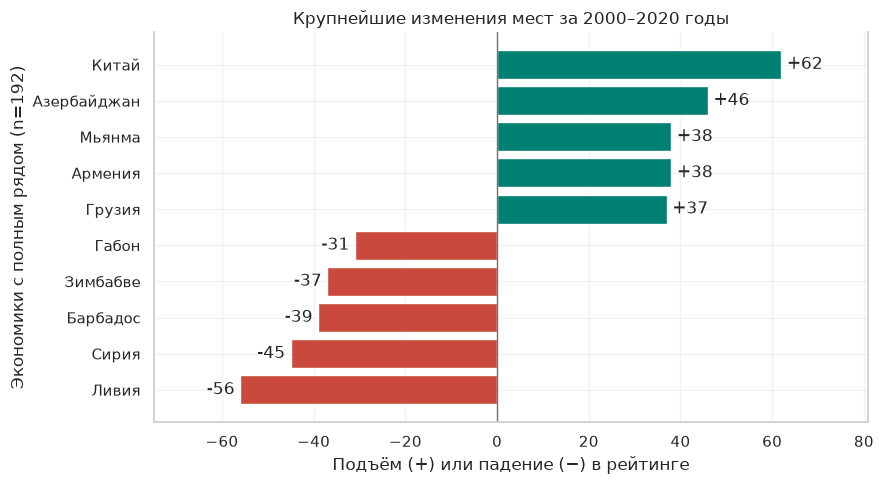

In [15]:
# Самые крупные подъёмы и падения в рейтинге
biggest_gains = economy_summary.nlargest(5, rank_gain)
biggest_losses = economy_summary.nsmallest(5, rank_gain)
rank_movers = pd.concat([biggest_gains, biggest_losses]).sort_values(rank_gain)


rank_columns = [first_rank, last_rank, rank_gain, gdp_growth]
show_table(rank_movers.set_index(ECONOMY_LABEL)[rank_columns].round(1))

fig, axis = plt.subplots(figsize=(9, 5))
rank_colors = np.where(rank_movers[rank_gain] > 0, GREEN, RED)
bars = axis.barh(rank_movers[ECONOMY_LABEL], rank_movers[rank_gain], color=rank_colors)
axis.bar_label(bars, fmt="%+d", padding=4)
axis.axvline(0, color="0.45", linewidth=1)
axis.margins(x=0.16)
axis.set(
    title=f"Крупнейшие изменения мест за {first_year}–{last_year} годы",
    xlabel="Подъём (+) или падение (−) в рейтинге",
    ylabel=f"Экономики с полным рядом (n={len(gdp_panel)})",
)
show_figure(fig, "09_economy_rank_movers.png")

### Какие страны рассматриваем подробнее?

Сначала берём страны с самыми большими изменениями ВВП или места.

Затем рассматриваем США, Китай, Германию, Японию, Индию и Россию как знакомые ориентиры.

На каждом парном рисунке слева показано место, справа собственное изменение ВВП. Индекс 100 означает уровень начального, 2000 года. Например, индекс 150 означает увеличение на 50%, а не ВВП в 150 денежных единиц.

In [16]:
# Общие шкалы для графиков траекторий
def plot_economy_trajectories(labels, title, filename):
    """Показать место и индекс ВВП одних и тех же стран."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
    fig.suptitle(title, fontsize=15)
    colors = ["#2769A3", "#C94A3D", "#007F73", "#8558A6", "#C78A12", "#566573"]

    for (code, label), color in zip(labels.items(), colors):
        axes[0].plot(
            panel_ranks.columns, panel_ranks.loc[code],
            label=label, color=color, linewidth=2.1,
        )
        axes[1].plot(
            gdp_index.columns, gdp_index.loc[code],
            color=color, linewidth=2.1,
        )

    axes[0].set(
        title=f"Место среди {len(gdp_panel)} экономик",
        ylabel="Место (1 — самое высокое)",
        ylim=(len(gdp_panel) + 2, 0),
        yticks=[1, *range(25, len(gdp_panel) + 1, 25)],
    )
    axes[1].set(
        title="Изменение уровня ВВП на душу по ППС",
        ylabel=f"Индекс ВВП ({first_year} год = 100)",
    )
    axes[1].axhline(100, color="0.6", linewidth=1, linestyle=":")

    for axis in axes:
        axis.axvspan(previous_year, last_year, color="0.5", alpha=0.1, linewidth=0)
        axis.set_xlabel("Год")
        axis.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))

    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="lower center", ncol=2, fontsize=10)
    show_figure(fig, filename, layout_rect=(0, 0.15, 1, 1))


gdp_index = gdp_panel.div(gdp_panel[first_year], axis=0) * 100

,Место 2000,Место 2019,Место 2020,Подъём мест 2000–2020,Подъём мест 2019–2020,ВВП 2020,"Изменение ВВП 2000–2020, %","Изменение ВВП 2019–2020, %"
Страна или территория,,,,,,,,
Китай,141,85,79,62,6,19215.1,372.6,2.1
Ливия,65,111,121,-56,-10,9978.7,-43.8,-30.4
Гайана,108,113,78,30,35,19234.1,139.7,43.5
Макао,14,1,18,-4,-17,59662.5,6.6,-55.3
Мальдивы,78,75,103,-25,-28,14243.0,3.7,-34.8


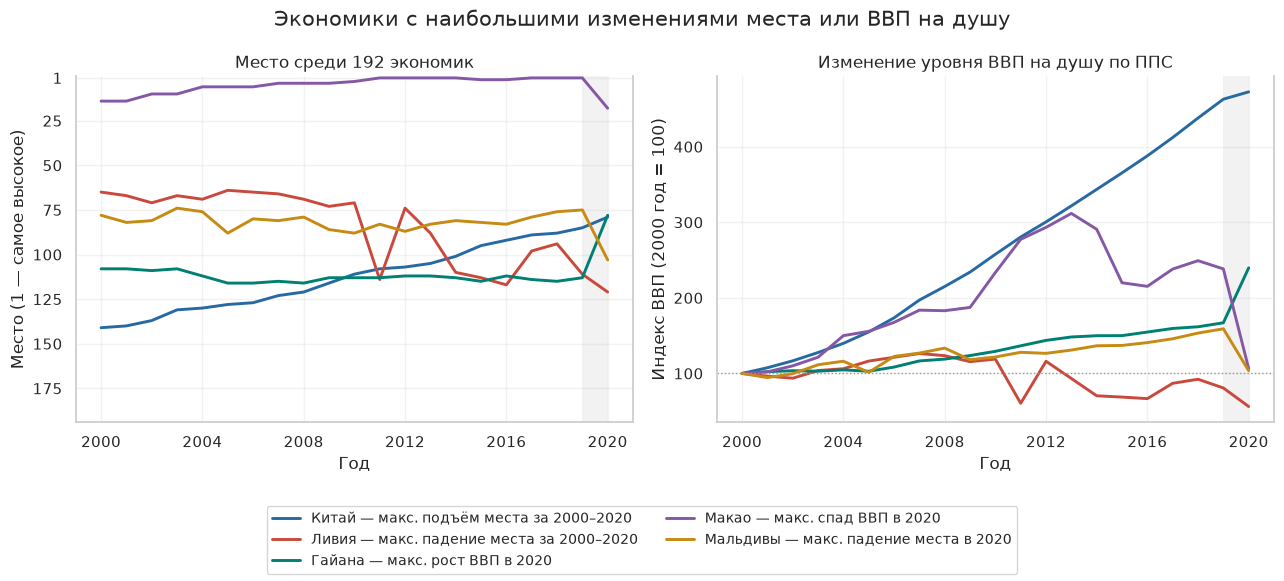

In [17]:
# Экономики с наибольшими изменениями
case_criteria = [
    (economy_summary[rank_gain].idxmax(), f"макс. подъём места за {first_year}–{last_year}"),
    (economy_summary[rank_gain].idxmin(), f"макс. падение места за {first_year}–{last_year}"),
    (economy_summary[recent_gdp_growth].idxmax(), f"макс. рост ВВП в {last_year}"),
    (economy_summary[recent_gdp_growth].idxmin(), f"макс. спад ВВП в {last_year}"),
    (economy_summary[recent_rank_gain].idxmin(), f"макс. падение места в {last_year}"),
]
case_labels = {}
for code, criterion in case_criteria:
    case_labels.setdefault(code, f"{economy_names.at[code]} — {criterion}")


show_table(economy_summary.loc[list(case_labels)].set_index(ECONOMY_LABEL).round(1))
plot_economy_trajectories(
    case_labels,
    "Экономики с наибольшими изменениями места или ВВП на душу",
    "10_economy_trajectories.png",
)

**Что показывают крайние примеры.** Гайана и Макао особенно заметно изменились в 2020 году. В паре графиков видно, сопровождается ли сдвиг места ростом или падением собственного ВВП. Эти страны выбраны именно из-за необычных изменений

,Место 2000,Место 2019,Место 2020,Подъём мест 2000–2020,Подъём мест 2019–2020,ВВП 2020,"Изменение ВВП 2000–2020, %","Изменение ВВП 2019–2020, %"
Страна или территория,,,,,,,,
США,16,11,10,6,1,67406.8,22.5,-2.5
Китай,141,85,79,62,6,19215.1,372.6,2.1
Германия,23,19,16,7,3,60299.6,20.7,-4.2
Япония,34,37,36,-2,1,44212.6,11.3,-4.0
Индия,158,134,134,24,0,7186.9,138.7,-6.7
Россия,57,49,47,10,2,36376.3,80.9,-2.5


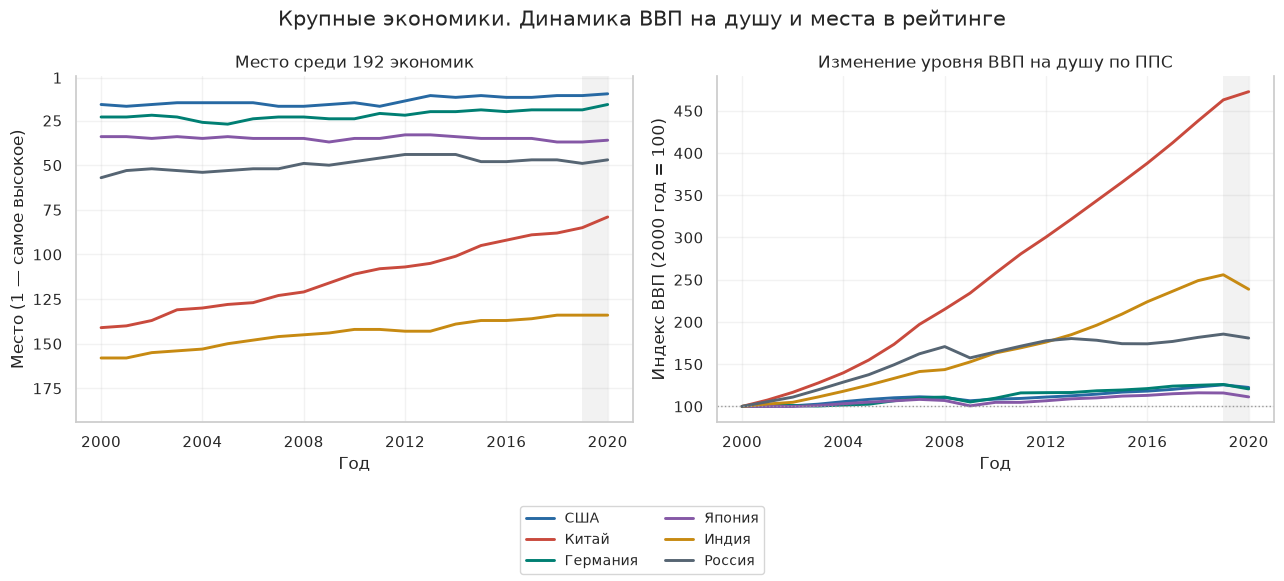

In [18]:
# Динамика выбранных крупных экономик
benchmark_codes = ["USA", "CHN", "DEU", "JPN", "IND", "RUS"]
benchmark_labels = economy_names.loc[benchmark_codes].to_dict()


show_table(economy_summary.loc[benchmark_codes].set_index(ECONOMY_LABEL).round(1))
plot_economy_trajectories(
    benchmark_labels,
    "Крупные экономики. Динамика ВВП на душу и места в рейтинге",
    "12_major_economies.png",
)
benchmark_growth = economy_summary.loc[benchmark_codes, gdp_growth]

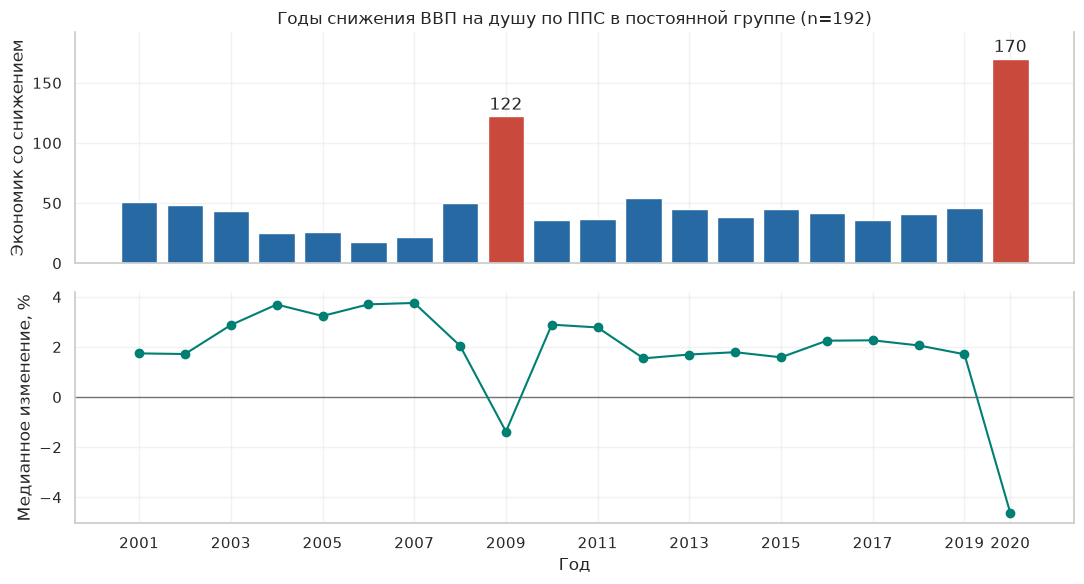

,Экономик со снижением,"Медианное изменение, %"
Год,,
2020,170,-4.62
2009,122,-1.38


In [19]:
# В какие годы снижение ВВП было наиболее распространённым
annual_growth = gdp_panel.pct_change(axis=1, fill_method=None).iloc[:, 1:] * 100
economies_with_decline = annual_growth.lt(0).sum(axis=0)
median_growth = annual_growth.median(axis=0)
most_declines = economies_with_decline.nlargest(2)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
year_colors = np.where(economies_with_decline.index.isin(most_declines.index), RED, BLUE)
axes[0].bar(economies_with_decline.index, economies_with_decline, color=year_colors)
for year, count in most_declines.items():
    axes[0].annotate(
        str(count), (year, count), xytext=(0, 5), textcoords="offset points",
        ha="center",
    )
axes[0].set(
    title=f"Годы снижения ВВП на душу по ППС в постоянной группе (n={len(gdp_panel)})",
    ylabel="Экономик со снижением",
    ylim=(0, len(gdp_panel)),
)
axes[1].axhline(0, color="0.45", linewidth=1)
axes[1].plot(median_growth.index, median_growth, color=GREEN, marker="o")
axes[1].set(xlabel="Год", ylabel="Медианное изменение, %")
axes[1].set_xticks(annual_growth.columns[::2].union(pd.Index([last_year])))
show_figure(fig, "11_economy_annual_changes.png")


show_table(pd.DataFrame({
    "Экономик со снижением": most_declines,
    "Медианное изменение, %": median_growth.loc[most_declines.index].round(2),
}))

## 5. Как сравниваем модели?

Задача модели — по ВВП и году оценить продолжительность жизни. Чтобы понять, работает ли она за пределами примеров обучения, часть данных заранее оставляем для проверки.

- **Обучение:** данные до 2015 года включительно для примерно 80% стран с известным ВВП.
- **Знакомые страны:** 2016–2020 годы для стран, которые были в обучении.
- **Новые страны:** 2016–2020 годы для стран, полностью исключённых из обучения.

Во время подбора модели используем только данные обучения. Три раза учимся на более ранних годах и проверяем на следующих: 2007–2009, 2010–2012 и 2013–2015. Это предварительная проверка, которую в таблице называем валидацией. Меньшая MAE означает меньшую среднюю ошибку в годах.

**С чем сравниваем:**

- «Медиана» всегда выдаёт одно число и не использует ВВП. Это простой ориентир: сложная модель должна быть полезнее него.
- «Диапазоны ВВП» делят страны на четыре группы дохода и дают по одному числу для каждой группы.
- Линейные модели проводят прямую по исходному ВВП или его логарифму; часть моделей также учитывает год.
- **Сплайн** — гладкая кривая, которая может изгибаться и менять скорость роста.
- Дерево и **градиентный бустинг** — более гибкие правила. Они могут хорошо описать обучение, но их пользу всё равно нужно проверить на других данных.


In [20]:
# Разделение по экономикам и годам
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
known_indices, _ = next(splitter.split(complete, groups=complete["iso3"]))
known_countries = set(complete.iloc[known_indices]["iso3"])
known_mask = complete["iso3"].isin(known_countries)
early_mask = complete["year"] <= LAST_TRAIN_YEAR

train = complete.loc[known_mask & early_mask]
tests = {
    "Знакомые страны": complete.loc[known_mask & ~early_mask],
    "Новые страны": complete.loc[~known_mask & ~early_mask],
}

assert set(train["iso3"]).isdisjoint(tests["Новые страны"]["iso3"])
assert set(tests["Знакомые страны"]["iso3"]).issubset(train["iso3"])
assert all(train["year"].max() < test["year"].min() for test in tests.values())


def split_row(part, frame):
    return {
        "Часть": part,
        "Строк": len(frame),
        "Экономик": frame["iso3"].nunique(),
        "Годы": f"{frame.year.min()}–{frame.year.max()}",
    }


split_summary = [split_row("Обучение", train)]
split_summary.extend(split_row(part, test) for part, test in tests.items())
show_table(pd.DataFrame(split_summary))

latest = data.loc[data["year"] > LAST_TRAIN_YEAR]
covered_rows = sum(len(test) for test in tests.values())
missing_economies = latest.loc[latest["gdp_ppp"].isna(), "iso3"].nunique()

,Часть,Строк,Экономик,Годы
0,Обучение,2498,159,2000–2015
1,Знакомые страны,795,159,2016–2020
2,Новые страны,200,40,2016–2020


In [21]:
# Временные фолды внутри обучающего периода
validation_windows = [(2007, 2009), (2010, 2012), (2013, 2015)]
cv_splits = []
cv_summary = []

for start_year, end_year in validation_windows:
    fit_indices = np.flatnonzero(train["year"] < start_year)
    validation_indices = np.flatnonzero(train["year"].between(start_year, end_year))
    cv_splits.append((fit_indices, validation_indices))
    cv_summary.append({
        "Обучение по год": start_year - 1,
        "Проверка": f"{start_year}–{end_year}",
        "Строк в обучении": len(fit_indices),
        "Строк в проверке": len(validation_indices),
    })

show_table(pd.DataFrame(cv_summary))

,Обучение по год,Проверка,Строк в обучении,Строк в проверке
0,2006,2007–2009,1077,470
1,2009,2010–2012,1547,474
2,2012,2013–2015,2021,477


Здесь проверяем две ситуации отдельно: более поздние годы уже известных стран и страны, которых модель раньше не видела. ВВП проверяемого года ей известен: без него оценка не строится.

In [22]:
# Модель на четырёх диапазонах ВВП
class IncomeBands(RegressorMixin, BaseEstimator):
    """Четыре диапазона ВВП с отдельным прогнозом-медианой."""

    def fit(self, X, y):
        gdp_quartiles = X["gdp_ppp"].quantile([0.25, 0.5, 0.75]).to_numpy()
        self.thresholds_ = np.round(gdp_quartiles, -3)

        bands = np.searchsorted(self.thresholds_, X["gdp_ppp"], side="right")
        medians = pd.Series(np.asarray(y)).groupby(bands).median()
        overall_median = float(np.median(y))
        self.medians_ = medians.reindex(range(4), fill_value=overall_median).to_numpy()
        return self

    def predict(self, X):
        bands = np.searchsorted(self.thresholds_, X["gdp_ppp"], side="right")
        return self.medians_[bands]

In [23]:
# Модели и сетки параметров
def select_columns(columns):
    return ColumnTransformer([("values", "passthrough", columns)])


smooth_inputs = ColumnTransformer([
    ("curve", SplineTransformer(knots="quantile", extrapolation="linear"), ["log_gdp"]),
    ("time", StandardScaler(), ["year"]),
])
models = {
    "Медиана": (DummyRegressor(strategy="median"), {}),
    "Диапазоны ВВП": (IncomeBands(), {}),
    "Линейная, ВВП": (
        make_pipeline(select_columns(["gdp_ppp"]), LinearRegression()),
        {},
    ),
    "Линейная, ВВП + год": (
        make_pipeline(select_columns(["gdp_ppp", "year"]), LinearRegression()),
        {},
    ),
    "Линейная, log ВВП + год": (
        make_pipeline(select_columns(["log_gdp", "year"]), LinearRegression()),
        {},
    ),
    "Сплайн, log ВВП + год": (
        make_pipeline(smooth_inputs, Ridge()),
        {
            "columntransformer__curve__n_knots": [3, 5, 8],
            "ridge__alpha": [0.1, 1, 10],
        },
    ),
    "Дерево": (
        make_pipeline(
            select_columns(["log_gdp", "year"]),
            DecisionTreeRegressor(random_state=42),
        ),
        {
            "decisiontreeregressor__max_depth": [2, 4, 6],
            "decisiontreeregressor__min_samples_leaf": [15, 40, 80],
        },
    ),
    "Градиентный бустинг": (
        make_pipeline(
            select_columns(["log_gdp", "year"]),
            HistGradientBoostingRegressor(random_state=42, early_stopping=False),
        ),
        {
            "histgradientboostingregressor__max_leaf_nodes": [7, 15],
            "histgradientboostingregressor__min_samples_leaf": [20, 60],
            "histgradientboostingregressor__max_iter": [100, 200],
        },
    ),
}

In [24]:
# Подбор параметров и выбор модели по MAE
fitted_models = {}
validation_results = []

for name, (estimator, grid) in models.items():
    search = GridSearchCV(
        estimator,
        grid,
        scoring="neg_mean_absolute_error",
        cv=cv_splits,
        error_score="raise",
    )
    search.fit(train[INPUTS], train["life"])
    fitted_models[name] = search.best_estimator_
    validation_results.append({
        "Модель": name,
        "MAE, лет": -search.best_score_,
        "Параметры": search.best_params_,
    })

validation = pd.DataFrame(validation_results).set_index("Модель").sort_values("MAE, лет")
cv_winner_name = validation.index[0]
cv_winner = fitted_models[cv_winner_name]

show_table(validation.drop(columns="Параметры").round(3))

,"MAE, лет"
Модель,
Градиентный бустинг,3.409
"Сплайн, log ВВП + год",3.452
"Линейная, log ВВП + год",3.565
Дерево,3.698
Диапазоны ВВП,3.733
"Линейная, ВВП + год",5.125
"Линейная, ВВП",5.456
Медиана,6.751


In [25]:
# Пороговые значения итоговой модели диапазонов
manual_model = fitted_models["Диапазоны ВВП"]
gdp_breaks = [-np.inf, *manual_model.thresholds_, np.inf]
ranges = pd.IntervalIndex.from_breaks(gdp_breaks, closed="left")
show_table(pd.DataFrame({
    "Диапазон ВВП": ranges.astype(str),
    "Прогноз жизни, лет": manual_model.medians_.round(2),
}))

,Диапазон ВВП,"Прогноз жизни, лет"
0,"[-inf, 5000.0)",59.96
1,"[5000.0, 15000.0)",70.72
2,"[15000.0, 35000.0)",73.82
3,"[35000.0, inf)",79.42


## 6. Какая модель точнее и какую выбираем для отчёта?

Дальше модели получают одни и те же проверочные строки. Метрики читаем так:

- **MAE:** средняя величина ошибки. MAE = 3 года означает, что прогноз в среднем отклоняется от значения в файле на 3 года; отдельные ошибки могут быть больше.
- **RMSE:** тоже ошибка в годах, но крупные промахи увеличивают её сильнее.
- **R²:** насколько модель лучше одного общего среднего. Чем ближе к 1, тем лучше она описывает различия значений в этой проверке; отрицательное значение означает результат хуже общего среднего.
- **Смещение:** склонность завышать или занижать оценки. Положительное число означает завышение.

 При подборе на ранних годах бустинг оказался немного лучше сплайна. Теперь посмотрим, сохранилось ли это преимущество на более поздних годах и новых странах.

In [26]:
# Метрики на знакомых и отложенных экономиках
test_results = []
predictions = []

for part, test in tests.items():
    for name, model in fitted_models.items():
        predicted = model.predict(test[INPUTS])
        residual = predicted - test["life"]
        test_results.append({
            "Модель": name, "Проверка": part,
            "MAE, лет": mean_absolute_error(test["life"], predicted),
            "RMSE, лет": np.sqrt(np.mean(residual**2)),
            "R²": r2_score(test["life"], predicted),
            "Смещение, лет": residual.mean(),
        })

        predictions.append(
            test.assign(Проверка=part, Модель=name, predicted=predicted, error=residual)
        )

scores = pd.DataFrame(test_results)
# Основная модель отчёта выбрана после разбора контрольных результатов.
# Это осознанная рекомендация, а не победитель исходной валидации.
winner_name = "Сплайн, log ВВП + год"
winner = fitted_models[winner_name]
all_predictions = pd.concat(predictions)
details = all_predictions.loc[all_predictions["Модель"].eq(winner_name)].copy()
selection_summary = pd.DataFrame([
    {"Этап": "Предварительный подбор на ранних годах", "Модель": cv_winner_name},
    {"Этап": "Рекомендация после контрольного сравнения", "Модель": winner_name},
])
selection_summary.to_csv(OUTPUT_DIRECTORY / "model_selection_summary.csv", index=False, encoding="utf-8-sig")


validation.to_csv(OUTPUT_DIRECTORY / "validation_metrics.csv", encoding="utf-8-sig")
scores.to_csv(OUTPUT_DIRECTORY / "test_metrics.csv", index=False, encoding="utf-8-sig")

model_comparison = scores.loc[scores["Модель"].isin(["Градиентный бустинг", "Сплайн, log ВВП + год"])].copy()
show_table(model_comparison.round(3))
model_comparison.to_csv(OUTPUT_DIRECTORY / "spline_vs_boosting.csv", index=False, encoding="utf-8-sig")

,Модель,Проверка,"MAE, лет","RMSE, лет",R²,"Смещение, лет"
5,"Сплайн, log ВВП + год",Знакомые страны,2.948,3.965,0.716,0.255
7,Градиентный бустинг,Знакомые страны,2.971,3.876,0.729,-0.337
13,"Сплайн, log ВВП + год",Новые страны,3.227,4.302,0.750,-0.402
15,Градиентный бустинг,Новые страны,3.888,4.998,0.662,-0.792


**Знакомые страны: по средней ошибке почти ничья.**

**Новые страны: сплайн заметно точнее.** 

**Решение - использовать сплайн.**

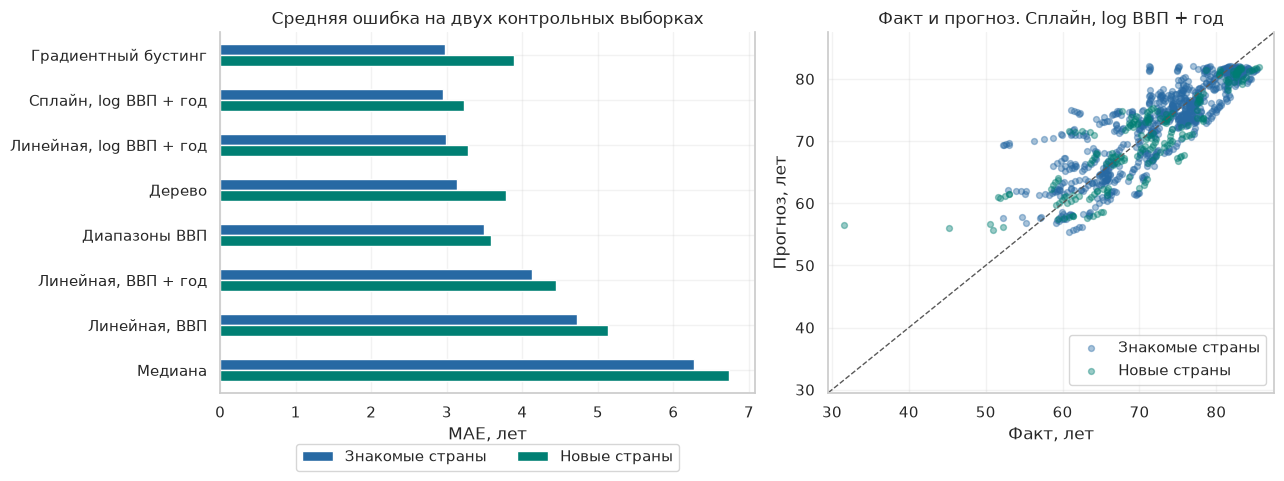

In [27]:
# Сравнение моделей и график факта против прогноза
palette = dict(zip(tests, [BLUE, GREEN]))
test_mae = scores.pivot(index="Модель", columns="Проверка", values="MAE, лет")
test_mae = test_mae.loc[validation.index, list(tests)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.2, 1]})
test_mae.plot.barh(ax=axes[0], color=palette)
axes[0].invert_yaxis()
axes[0].set(title="Средняя ошибка на двух контрольных выборках", xlabel="MAE, лет", ylabel="")
axes[0].legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

for part, rows in details.groupby("Проверка"):
    axes[1].scatter(
        rows["life"], rows["predicted"],
        s=18, alpha=0.4, color=palette[part], label=part,
    )

limits = [
    min(details["life"].min(), details["predicted"].min()) - 2,
    max(details["life"].max(), details["predicted"].max()) + 2,
]
axes[1].plot(limits, limits, color="0.35", linestyle="--", linewidth=1)
axes[1].set(
    title=f"Факт и прогноз. {winner_name}",
    xlabel="Факт, лет",
    ylabel="Прогноз, лет",
    xlim=limits,
    ylim=limits,
)
axes[1].legend(loc="lower right")
show_figure(fig, "06_model_quality.png")

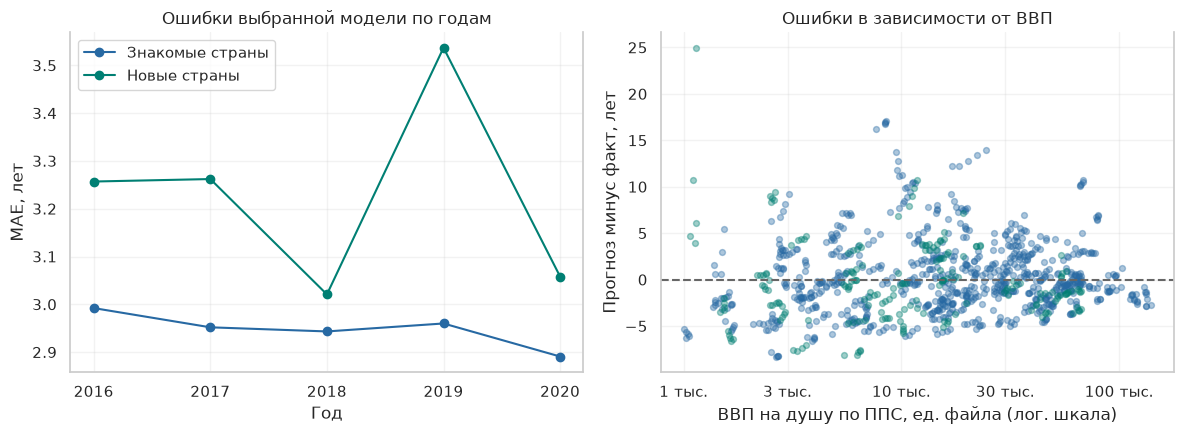

,Страна или территория,Год,ВВП на жителя по ППС,"Продолжительность жизни, лет","Оценка модели, лет","Оценка минус факт, лет",Проверка
778,Центральноафриканская Республика,2019,1145.10,31.53,56.49,24.96,Новые страны
3028,Нигерия,2016,8534.69,52.19,69.32,17.13,Знакомые страны
3027,Нигерия,2017,8396.78,52.40,69.39,16.99,Знакомые страны
3026,Нигерия,2018,8362.62,52.67,69.55,16.88,Знакомые страны
3025,Нигерия,2019,8361.79,53.01,69.74,16.73,Знакомые страны


In [28]:
# Ошибки по годам и уровням ВВП
year_mae = details.assign(abs_error=details["error"].abs()).pivot_table(
    index="year", columns="Проверка", values="abs_error", aggfunc="mean",
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
year_mae.plot(ax=axes[0], marker="o", color=palette)
axes[0].set(title="Ошибки выбранной модели по годам", xlabel="Год", ylabel="MAE, лет")
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend(title="")

for part, rows in details.groupby("Проверка"):
    axes[1].scatter(
        rows["gdp_ppp"], rows["error"], color=palette[part], s=18, alpha=0.38,
    )
axes[1].axhline(0, color="0.4", linestyle="--")
axes[1].set(title="Ошибки в зависимости от ВВП", ylabel="Прогноз минус факт, лет")
format_gdp_axis(axes[1])
show_figure(fig, "07_residuals.png")

largest_errors = details["error"].abs().nlargest(5).index
error_columns = [ECONOMY_LABEL, "year", "gdp_ppp", "life", "predicted", "error", "Проверка"]

show_table(details.loc[largest_errors, error_columns].round(2))

На графике факт - оценка идеальные точки лежали бы на пунктирной диагонали. Чем точка дальше от неё, тем больше промах.

На графике по годам смотрим, меняется ли средняя ошибка. На графике ошибок от ВВП ноль означает точное совпадение, положительное значение модель завысила жизнь, отрицательное занизила. Таблица показывает пять самых больших промахов сплайна.

Даже одинаковые ВВП и год не делают страны одинаковыми. Поэтому оценку модели нельзя выдавать за точное значение для конкретной страны: в данных остаются различия, которых эти два признака не объясняют.

## 7. Какие страны модель позволяет различить?

Берём один год, 2019, и две пары:

- **Бурунди и Швейцария:** ВВП сильно различается, страны далеко друг от друга на горизонтальной оси.
- **Бразилия и Китай:** ВВП близок, страны стоят рядом в средней части графика.

Сплайн даёт каждой стране оценку жизни по её ВВП и году. Но если бы обучение содержало немного другой набор стран, линия тоже немного изменилась бы. **Доверительная полоса** показывает эту неточность средней линии.

Чтобы её оценить, 1000 раз набираем новую обучающую выборку из тех же стран случайным выбором с повторениями и заново обучаем сплайн. Все годы одной страны берём вместе. Для каждой пары в каждом повторе считаем разность оценок.

**Как поймём результат:** если весь интервал разности выше нуля, модель устойчиво даёт второй стране более высокую оценку. Если интервал захватывает ноль, разница слишком неопределённа, чтобы уверенно её утверждать. Это не доказывает равенство стран.


In [29]:
# Профили прогнозов при разных значениях ВВП
plot_year = 2019
gdp_grid = np.geomspace(train.gdp_ppp.min(), train.gdp_ppp.max(), 400)
model_inputs = pd.DataFrame({
    "gdp_ppp": gdp_grid,
    "log_gdp": np.log(gdp_grid),
    "year": plot_year,
})

In [30]:
# Кластерный bootstrap выбранной регрессии и двух сравнений
example_codes = ["BDI", "CHE", "BRA", "CHN"]
country_examples = snapshot.set_index("iso3").loc[example_codes].copy()
country_inputs = country_examples[INPUTS]
bootstrap_inputs = pd.concat([model_inputs, country_inputs], ignore_index=True)
country_groups = [group.index.to_numpy() for _, group in train.groupby("iso3", sort=True)]
rng = np.random.default_rng(RANDOM_SEED)
bootstrap_predictions = np.empty((BOOTSTRAP_REPEATS, len(bootstrap_inputs)))
for repeat in range(BOOTSTRAP_REPEATS):
    drawn_groups = rng.integers(0, len(country_groups), size=len(country_groups))
    drawn_rows = np.concatenate([country_groups[i] for i in drawn_groups])
    bootstrap_model = clone(winner)
    bootstrap_model.fit(train.loc[drawn_rows, INPUTS], train.loc[drawn_rows, "life"])
    bootstrap_predictions[repeat] = bootstrap_model.predict(bootstrap_inputs)

assert np.isfinite(bootstrap_predictions).all()
curve_lower, curve_upper = np.quantile(
    bootstrap_predictions[:, :len(gdp_grid)], [0.025, 0.975], axis=0,
)
country_bootstrap = bootstrap_predictions[:, len(gdp_grid):]
country_predictions = winner.predict(country_inputs)
country_lower, country_upper = np.quantile(country_bootstrap, [0.025, 0.975], axis=0)
country_table = country_examples[[ECONOMY_LABEL, "gdp_ppp", "life"]].rename(columns={
    "gdp_ppp": "ВВП 2019", "life": "Факт жизни, лет",
})
country_table["Оценка модели, лет"] = country_predictions
country_table["95% ДИ: нижняя"] = country_lower
country_table["95% ДИ: верхняя"] = country_upper

comparison_pairs = [("BDI", "CHE"), ("BRA", "CHN")]
tail_probability = 0.05 / (2 * len(comparison_pairs))
comparison_rows = []
for left, right in comparison_pairs:
    i, j = example_codes.index(left), example_codes.index(right)
    delta = country_bootstrap[:, j] - country_bootstrap[:, i]
    lower, upper = np.quantile(delta, [tail_probability, 1 - tail_probability])
    comparison_rows.append({
        "Сравнение (вторая − первая)": f"{economy_names.at[right]} − {economy_names.at[left]}",
        "Разность оценок жизни, лет": country_predictions[j] - country_predictions[i],
        "97,5% ДИ: нижняя": lower,
        "97,5% ДИ: верхняя": upper,
        "Различие установлено": "Да" if lower > 0 or upper < 0 else "Нет",
    })
country_comparisons = pd.DataFrame(comparison_rows)
show_table(country_table.round(2))
show_table(country_comparisons.round(2))
country_table.to_csv(OUTPUT_DIRECTORY / "country_prediction_intervals.csv", encoding="utf-8-sig")
country_comparisons.to_csv(
    OUTPUT_DIRECTORY / "country_prediction_comparisons.csv", index=False, encoding="utf-8-sig",
)

,Страна или территория,ВВП 2019,"Факт жизни, лет","Оценка модели, лет",95% ДИ: нижняя,95% ДИ: верхняя
Код страны,,,,,,
BDI,Бурунди,1054.73,62.18,56.16,54.01,58.41
CHE,Швейцария,81694.63,83.90,81.84,80.36,83.10
BRA,Бразилия,18018.62,75.81,74.43,72.98,76.07
CHN,Китай,18820.59,77.94,74.62,73.14,76.15


,Сравнение (вторая − первая),"Разность оценок жизни, лет","97,5% ДИ: нижняя","97,5% ДИ: верхняя",Различие установлено
0,Швейцария − Бурунди,25.68,22.61,28.32,Да
1,Китай − Бразилия,0.19,-0.22,0.41,Нет


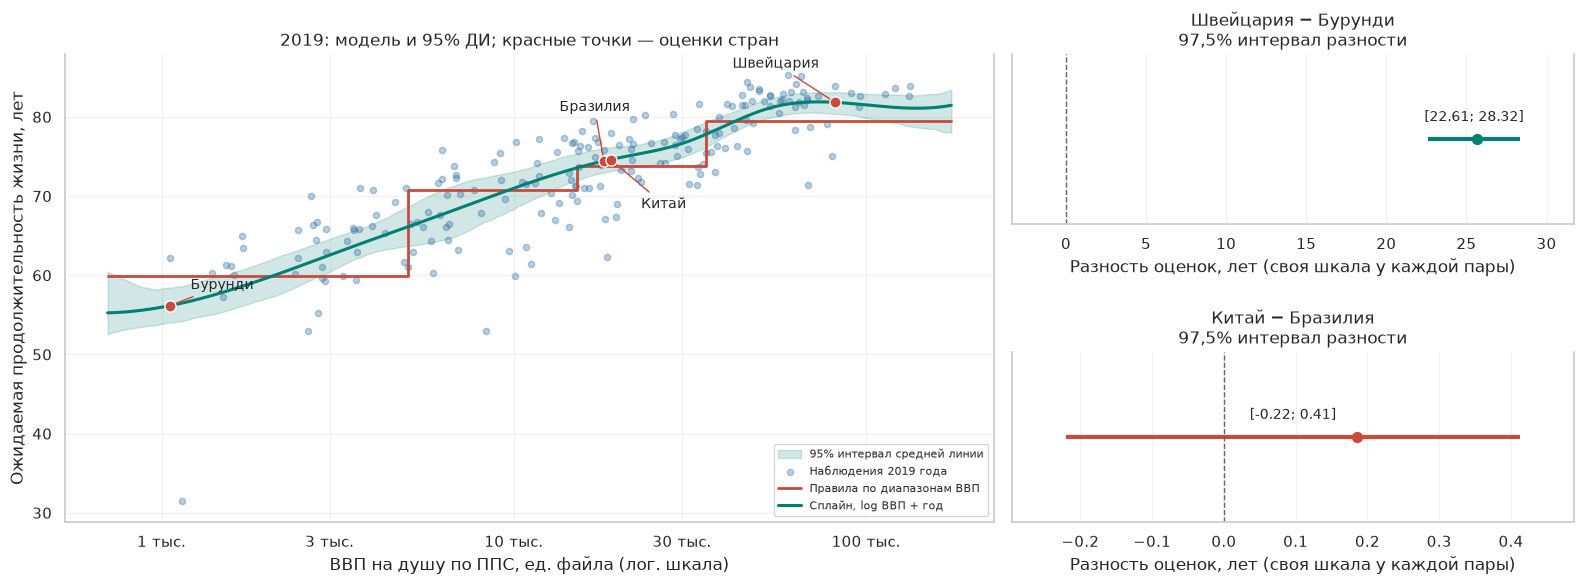

In [31]:
# Общий график: регрессия с ДИ, страны и интервалы разностей
fig = plt.figure(figsize=(16, 6))
layout = fig.add_gridspec(1, 2, width_ratios=[1.65, 1])
axis = fig.add_subplot(layout[0, 0])
right_layout = layout[0, 1].subgridspec(2, 1, hspace=0.75)
comparison_axes = [fig.add_subplot(right_layout[k, 0]) for k in range(2)]
axis.fill_between(
    gdp_grid, curve_lower, curve_upper,
    color=GREEN, alpha=0.18, label="95% интервал средней линии",
)
axis.scatter(
    snapshot["gdp_ppp"], snapshot["life"],
    s=20, alpha=0.33, color=BLUE, label=f"Наблюдения {plot_year} года",
)
axis.step(
    gdp_grid, manual_model.predict(model_inputs),
    where="post", color=RED, label="Правила по диапазонам ВВП", linewidth=2,
)
axis.plot(gdp_grid, winner.predict(model_inputs), color=GREEN, label=winner_name, linewidth=2.2)

smooth_name = "Сплайн, log ВВП + год"
if winner_name != smooth_name:
    axis.plot(
        gdp_grid, fitted_models[smooth_name].predict(model_inputs),
        color="#7752A1", linestyle="--", label=smooth_name, linewidth=2,
    )

for k, code in enumerate(example_codes):
    gdp = country_examples.at[code, "gdp_ppp"]
    predicted = country_predictions[k]
    axis.scatter(gdp, predicted, color=RED, edgecolor="white", s=65, zorder=5)
    axis.annotate(
        economy_names.at[code], (gdp, predicted),
        xytext=[(15, 12), (-12, 25), (-32, 36), (22, -35)][k],
        textcoords="offset points", fontsize=10,
        ha="right" if code == "CHE" else "left",
        arrowprops={"arrowstyle": "-", "color": RED},
    )
axis.set(ylabel=LIFE_LABEL, title=f"{plot_year}: модель и 95% ДИ; красные точки — оценки стран")
format_gdp_axis(axis)
axis.legend(fontsize=8, loc="lower right")
for k, row in country_comparisons.iterrows():
    comparison_axis = comparison_axes[k]
    lower, upper = row["97,5% ДИ: нижняя"], row["97,5% ДИ: верхняя"]
    color = GREEN if row["Различие установлено"] == "Да" else RED
    comparison_axis.hlines(0, lower, upper, color=color, linewidth=3)
    comparison_axis.scatter(row["Разность оценок жизни, лет"], 0, color=color, s=50, zorder=3)
    comparison_axis.annotate(
        f"[{lower:.2f}; {upper:.2f}]", ((lower + upper) / 2, 0),
        xytext=(0, 13), textcoords="offset points", ha="center", fontsize=10,
    )
    comparison_axis.axvline(0, color="0.4", linestyle="--", linewidth=1)
    left, right = min(lower, 0), max(upper, 0)
    padding = max((right - left) * 0.12, 0.05)
    comparison_axis.set(
        title=row["Сравнение (вторая − первая)"] + "\n97,5% интервал разности",
        xlabel="Разность оценок, лет (своя шкала у каждой пары)",
        xlim=(left - padding, right + padding), ylim=(-0.6, 0.6), yticks=[],
    )
show_figure(fig, "08_model_profile.png")

**Швейцария и Бурунди: разницу видно даже с учётом неточности.** Сплайн даёт Швейцарии оценку жизни на 25.68 года выше. Интервал разницы — от +22.61 до +28.32 года. Он целиком выше нуля: в повторных расчётах преимущество Швейцарии сохраняется. Это убедительное различие оценок модели.

**Китай и Бразилия: уверенно разделить не получилось.** Оценка для Китая выше всего на 0.19 года. Интервал разницы — от -0.22 до +0.41 года, то есть включает и небольшое преимущество Бразилии, и небольшое преимущество Китая. Разница слишком неопределённа, чтобы утверждать её уверенно. Это не означает, что реальные показатели стран одинаковы.

**Что этим показали.** Большую разницу между Швейцарией и Бурунди модель выделяет уверенно. Разницу между Китаем и Бразилией нет.


In [32]:
# Ручной ввод ВВП и года
def predict_life(gdp_ppp, year):
    """Оценка ожидаемой продолжительности жизни при известном ВВП."""
    gdp_ppp = float(gdp_ppp)
    year = float(year)

    if not np.isfinite(gdp_ppp) or gdp_ppp <= 0:
        raise ValueError("Укажите конечный положительный ВВП на душу по ППС.")
    if not year.is_integer() or not data["year"].min() <= year <= data["year"].max():
        raise ValueError(f"Укажите целый год из диапазона {data.year.min()}–{data.year.max()}.")
    if not train["gdp_ppp"].min() <= gdp_ppp <= train["gdp_ppp"].max():
        raise ValueError("ВВП за пределами диапазона обучающей выборки.")

    inputs = pd.DataFrame({
        "gdp_ppp": [gdp_ppp],
        "log_gdp": [np.log(gdp_ppp)],
        "year": [int(year)],
    })
    return float(winner.predict(inputs)[0])


# Измените значения для ручного ввода.
example_gdp = 15000
example_year = 2019

estimate = predict_life(example_gdp, example_year)

show_table(pd.DataFrame([{
    "ВВП на жителя по ППС": example_gdp,
    "Год": example_year,
    "Оценка сплайна, лет": round(estimate, 2),
}]))

,ВВП на жителя по ППС,Год,"Оценка сплайна, лет"
0,15000,2019,73.53


**Как понимать свой результат.** Можно изменить ВВП и год в ячейке выше и получить оценку сплайна. Это приблизительная средняя оценка по двум признакам.

In [33]:
# Итоговые ошибки основной модели по годам
show_table(year_mae.round(2))

Проверка,Знакомые страны,Новые страны
Год,,
2016,2.99,3.26
2017,2.95,3.26
2018,2.94,3.02
2019,2.96,3.54
2020,2.89,3.06


In [34]:
# Проверка эффекта логарифмирования при одинаковом признаке года
linear_names = ["Линейная, ВВП + год", "Линейная, log ВВП + год"]
linear_scores = scores.loc[scores["Модель"].isin(linear_names)]

show_table(linear_scores.pivot(index="Модель", columns="Проверка", values="MAE, лет").round(3))

Проверка,Знакомые страны,Новые страны
Модель,,
"Линейная, log ВВП + год",2.989,3.285
"Линейная, ВВП + год",4.128,4.450


В таблице выше сравниваются две линейные модели: у обеих есть год, меняется только вид ВВП. Модель с логарифмом даёт меньшую ошибку на обеих проверках. Значит, преобразование полезно не только для рисунка: оно помогает модели описать изгиб зависимости.